# 00 — Conferência dos dados antes da L2

Este notebook registra a conferência dos arquivos já existentes. **Ainda não calcula o expoente α.** Primeiro precisamos entender como cada setor e cada pronto-atendimento aparece nas tabelas.

A análise principal considera somente estabelecimentos do tipo 73 do CNES que atendem o SUS. A versão com todos os estabelecimentos é o teste de robustez.

**Combinado com a autora:** todas as análises e figuras devem ficar em notebooks, com código e resultados visíveis. Novas decisões metodológicas precisam ser discutidas antes de executadas. Scripts ficam para coleta de dados; os antigos são preservados como histórico.

## 1. O que vamos conferir?

- Há um arquivo por capital em cada versão?
- Cada código de setor representa uma única observação?
- População e área se repetem em linhas do mesmo setor?
- Quais unidades não receberam nenhum setor?
- A malha original do IBGE explica as linhas repetidas?

Não apagamos, corrigimos nem sobrescrevemos os CSVs de entrada.


In [1]:
from pathlib import Path
import sys
import unicodedata

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Permite abrir o notebook a partir da raiz ou da pasta notebooks/.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
PROC = RAIZ / "dados" / "processados"
DIST = PROC / "distancias"
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo  # Apenas cores e fontes; a análise está neste notebook.
estilo.aplicar()

def slug(nome):
    return unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode().split(" - ")[0].lower().replace(" ", "_")

capitais = pd.read_csv(PROC / "capitais_resumo.csv", dtype={"co_ibge7": str})
unidades = pd.read_csv(PROC / "pa_capitais_corrigido.csv", dtype={"CO_CNES": str})
nome_capital = dict(zip(capitais.municipio.map(slug), capitais.municipio))
print("Pasta do projeto:", RAIZ)
print("Versão do Python:", sys.version.split()[0])
print("Unidades no cadastro:", len(unidades), "| SUS:", int(unidades.atende_sus.sum()))


Pasta do projeto: /home/liasucf/ciencia-de-cidades
Versão do Python: 3.12.3
Unidades no cadastro: 274 | SUS: 245


## 2. Ler os setores sem transformá-los

Cada linha contém a população, a área oficial do setor e a distância calculada pela rua até a unidade mais próxima. Preservamos o nome do arquivo para rastrear cada observação.

O filtro já previsto no plano mantém setores com população positiva, ligação à rua de até 2 km e distância finita. **Aplicar esse filtro não resolve eventuais repetições do mesmo código de setor.**


In [2]:
def ler_versao(sufixo):
    partes = []
    for arquivo in sorted(DIST.glob(f"*_{sufixo}_setores.csv")):
        tabela = pd.read_csv(arquivo, dtype={"CD_SETOR": str, "CO_CNES": str})
        chave = arquivo.name.removesuffix(f"_{sufixo}_setores.csv")
        tabela["capital"] = nome_capital[chave]
        tabela["arquivo"] = arquivo.name
        partes.append(tabela)
    if not partes:
        raise FileNotFoundError(f"Nenhum arquivo encontrado para {sufixo}")
    return pd.concat(partes, ignore_index=True)

brutos = {"SUS": ler_versao("drive_sus"), "Todos": ler_versao("drive")}

def mascara_prevista(tabela):
    return (tabela.populacao > 0) & (tabela.ligacao_m <= 2000) & np.isfinite(tabela.d_m)

resumo = []
for versao, tabela in brutos.items():
    validos = tabela.loc[mascara_prevista(tabela)]
    esperadas = unidades.loc[unidades.atende_sus] if versao == "SUS" else unidades
    resumo.append({
        "versao": versao,
        "capitais": tabela.capital.nunique(),
        "linhas_brutas": len(tabela),
        "codigos_distintos": tabela.CD_SETOR.nunique(),
        "linhas_apos_filtro": len(validos),
        "codigos_apos_filtro": validos.CD_SETOR.nunique(),
        "unidades_cadastro": len(esperadas),
        "unidades_com_setores_validos": validos.CO_CNES.nunique(),
    })
display(pd.DataFrame(resumo).set_index("versao"))


,capitais,linhas_brutas,codigos_distintos,linhas_apos_filtro,codigos_apos_filtro,unidades_cadastro,unidades_com_setores_validos
versao,,,,,,,
SUS,26,93019,92782,91043,90985,245,245
Todos,26,93019,92782,91043,90985,274,273


## 3. Uma linha é sempre um setor?

Se um mesmo código aparece três vezes e a população total do setor é repetida em cada linha, somar essas linhas conta a população três vezes. A área também pode ser contada mais de uma vez.

As tabelas abaixo são um **diagnóstico**, não uma autorização para escolher uma linha e descartar as outras. As distâncias podem ser diferentes e até apontar unidades distintas.


In [3]:
diagnostico = []
for versao, tabela in brutos.items():
    for etapa, dados in [
        ("Antes do filtro", tabela),
        ("Após o filtro", tabela.loc[mascara_prevista(tabela)])
    ]:
        repetidos = dados.loc[dados.duplicated("CD_SETOR", keep=False)]
        habitados = repetidos.loc[repetidos.populacao > 0]
        # Só usamos uma linha por código nesta conta diagnóstica porque
        # população e área devem ser atributos únicos do setor.
        constantes = repetidos.groupby("CD_SETOR")[["populacao", "AREA_KM2"]].nunique(dropna=False)
        assert (constantes <= 1).all().all(), "Atributos conflitantes: investigar antes de somar."
        diagnostico.append({
            "versao": versao, "etapa": etapa,
            "setores_repetidos": repetidos.CD_SETOR.nunique(),
            "setores_repetidos_habitados": habitados.CD_SETOR.nunique(),
            "linhas_de_setores_repetidos": len(repetidos),
            "populacao_contada_a_mais": int(habitados.populacao.sum() - habitados.drop_duplicates("CD_SETOR").populacao.sum()),
            "area_contada_a_mais_km2": repetidos.AREA_KM2.sum() - repetidos.drop_duplicates("CD_SETOR").AREA_KM2.sum(),
            "setores_com_unidades_distintas": int((repetidos.groupby("CD_SETOR").CO_CNES.nunique() > 1).sum()),
        })
display(pd.DataFrame(diagnostico).set_index(["versao", "etapa"]))

sus = brutos["SUS"]
repetidos = sus.loc[sus.duplicated("CD_SETOR", keep=False)]
display(repetidos.groupby("capital").agg(
    linhas=("CD_SETOR", "size"),
    setores_distintos=("CD_SETOR", "nunique")
))
display(repetidos.loc[repetidos.populacao > 0, [
    "capital", "CD_SETOR", "populacao", "AREA_KM2", "CO_CNES", "d_m", "ligacao_m"
]].head(12))


setores_repetidos  setores_repetidos_habitados  \
versao etapa                                                             
SUS    Antes do filtro                 63                           48   
       Após o filtro                   26                           26   
Todos  Antes do filtro                 63                           48   
       Após o filtro                   26                           26   

                        linhas_de_setores_repetidos  populacao_contada_a_mais  \
versao etapa                                                                    
SUS    Antes do filtro                          300                     49432   
       Após o filtro                             84                     28327   
Todos  Antes do filtro                          300                     49432   
       Após o filtro                             84                     28327   

                        area_contada_a_mais_km2  \
versao etapa                                      
SUS    Antes do filtro             23302.496321   
       Após o filtro                1172.337470   
Todos  Antes do filtro             23302.496321   
       Após o filtro                1172.337470   

                        setores_com_unidades_distintas  
versao etapa                                            
SUS    Antes do filtro                               6  
       Após o filtro                                 1  
Todos  Antes do filtro                               6  
       Após o filtro                                 2

,linhas,setores_distintos
capital,,
Belo Horizonte - MG,2,1
Belém - PA,22,5
Boa Vista - RR,17,5
Florianópolis - SC,29,6
Maceió - AL,2,1
Manaus - AM,40,2
Palmas - TO,2,1
Porto Alegre - RS,6,3
Recife - PE,2,1


,capital,CD_SETOR,populacao,AREA_KM2,CO_CNES,d_m,ligacao_m
1574,Belém - PA,150140265000073,12,3.064910,7260784,36866.035719,20952.817673
1575,Belém - PA,150140265000073,12,3.064910,7260784,35041.249796,19128.031750
1621,Belém - PA,150140265000125,540,55.622745,7260784,33927.843752,17971.414717
1622,Belém - PA,150140265000125,540,55.622745,7260784,34144.544846,18188.115810
1623,Belém - PA,150140265000125,540,55.622745,7260784,33401.216698,17444.787663
1624,Belém - PA,150140265000125,540,55.622745,7260784,31200.715622,15244.286587
1625,Belém - PA,150140265000125,540,55.622745,7260784,32471.010271,16514.581236
1626,Belém - PA,150140265000125,540,55.622745,7260784,30858.388015,14901.958979
1702,Belém - PA,150140267000103,573,14.299085,7260784,13069.972939,5537.808199
1703,Belém - PA,150140267000103,573,14.299085,7260784,13368.770572,5868.222999


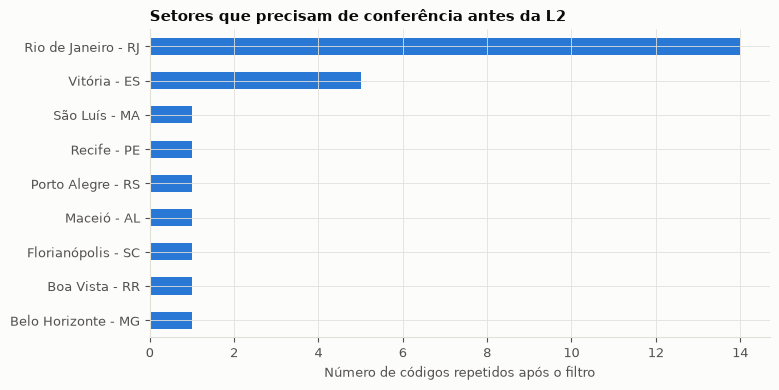

In [4]:
validos = sus.loc[mascara_prevista(sus)]
repetidos_validos = validos.loc[validos.duplicated("CD_SETOR", keep=False)]
por_capital = repetidos_validos.groupby("capital").CD_SETOR.nunique().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
por_capital.plot.barh(ax=ax, color=estilo.AZUL)
ax.set_xlabel("Número de códigos repetidos após o filtro")
ax.set_ylabel("")
ax.set_title("Setores que precisam de conferência antes da L2")
plt.show()


## 4. Conferir a geometria no arquivo original do IBGE

Buscamos na malha original um dos setores repetidos. Se houver vários polígonos com o mesmo código e a mesma área oficial total, a repetição começou antes da regressão, na leitura da geometria.

A área geométrica projetada abaixo serve apenas para conferir as partes. **Ela não substitui a área oficial do IBGE**, que é a variável prevista no plano. A projeção pode produzir valores um pouco diferentes.


,CD_SETOR,AREA_KM2,tipo_geometria,area_parte_projetada_km2
0,150140265000073,3.06491,Polygon,0.019026
1,150140265000073,3.06491,Polygon,3.060808


Número de partes na malha original: 2
Área oficial repetida em todas as partes: True


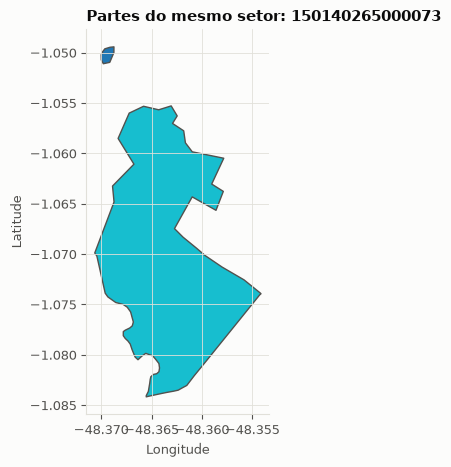

In [5]:
codigo_exemplo = repetidos.loc[repetidos.populacao > 0, "CD_SETOR"].iloc[0]
capital_exemplo = repetidos.loc[repetidos.CD_SETOR == codigo_exemplo, "capital"].iloc[0]
uf_exemplo = capital_exemplo.split(" - ")[1]
geometrias = gpd.read_file(
    RAIZ / "dados" / "ibge" / "setores_gpkg" / f"{uf_exemplo}_setores_CD2022.gpkg",
    where=f"CD_SETOR='{codigo_exemplo}'",
    columns=["CD_SETOR", "AREA_KM2"]
)
conferencia_geometria = geometrias[["CD_SETOR", "AREA_KM2"]].copy()
conferencia_geometria["tipo_geometria"] = geometrias.geom_type
conferencia_geometria["area_parte_projetada_km2"] = geometrias.to_crs(5880).area / 1e6
display(conferencia_geometria)
print("Número de partes na malha original:", len(geometrias))
print("Área oficial repetida em todas as partes:", geometrias.AREA_KM2.nunique() == 1)

fig, ax = plt.subplots(figsize=(6, 5))
geometrias.reset_index(drop=True).plot(ax=ax, column=np.arange(len(geometrias)),
                                     cmap="tab10", edgecolor=estilo.TEXTO_2)
ax.set_title(f"Partes do mesmo setor: {codigo_exemplo}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.ticklabel_format(useOffset=False)
plt.show()


## 5. Qual unidade não aparece na versão com todos?

A ausência de uma área estimada **não significa ausência de atendimento real**. Aqui os setores são representados por pontos e associados à unidade escolhida pelo algoritmo.

Comparamos o cadastro com as unidades que aparecem nas distâncias. As unidades privadas naturalmente não devem aparecer na versão só SUS.


In [6]:
faltantes = {}
for versao, tabela in brutos.items():
    cadastro = unidades.loc[unidades.atende_sus] if versao == "SUS" else unidades
    validos = tabela.loc[mascara_prevista(tabela)]
    falta = cadastro.loc[~cadastro.CO_CNES.isin(validos.CO_CNES)].copy()
    falta["linhas_atribuidas_antes_do_filtro"] = [
        int((tabela.CO_CNES == codigo).sum()) for codigo in falta.CO_CNES
    ]
    faltantes[versao] = falta
    print(f"Versão {versao}: {len(falta)} unidades sem setores válidos")
    display(falta[["CO_CNES", "municipio", "NO_FANTASIA", "atende_sus",
                   "linhas_atribuidas_antes_do_filtro"]])

codigo_bom_jesus = "6537650"
comparacao_bom_jesus = []
for versao, tabela in brutos.items():
    atribuicoes = tabela.loc[tabela.CO_CNES == codigo_bom_jesus]
    comparacao_bom_jesus.append({
        "versao": versao,
        "linhas_atribuidas": len(atribuicoes),
        "setores_distintos": atribuicoes.CD_SETOR.nunique(),
        "linhas_validas": int(mascara_prevista(atribuicoes).sum()),
    })
display(pd.DataFrame(comparacao_bom_jesus).set_index("versao"))


Versão SUS: 0 unidades sem setores válidos


,CO_CNES,municipio,NO_FANTASIA,atende_sus,linhas_atribuidas_antes_do_filtro


Versão Todos: 1 unidades sem setores válidos


,CO_CNES,municipio,NO_FANTASIA,atende_sus,linhas_atribuidas_antes_do_filtro
164,6537650,Porto Alegre - RS,PRONTO ATENDIMENTO BOM JESUS,True,0


,linhas_atribuidas,setores_distintos,linhas_validas
versao,,,
SUS,476,476,471
Todos,0,0,0


## 6. Conferir se unidades se ligam ao mesmo nó da rua

O script anterior elimina fontes com nós repetidos antes de executar o Dijkstra. Por isso verificamos as ligações em Porto Alegre. Esta célula usa somente a rede já guardada no projeto e as coordenadas corrigidas, sem consultas à internet.

A rede é projetada em metros, como no cálculo original. Se duas unidades se ligarem ao mesmo nó, isso precisa ser discutido antes de alterar a regra de associação.


In [7]:
import osmnx as ox

pa_poa = unidades.loc[unidades.municipio == "Porto Alegre - RS"].copy()
pa_poa = gpd.GeoDataFrame(
    pa_poa, geometry=gpd.points_from_xy(pa_poa.lon, pa_poa.lat), crs=4326
).to_crs(32722)
grafo_poa = ox.load_graphml(RAIZ / "dados" / "osm" / "porto_alegre_drive.graphml")
grafo_poa = ox.truncate.largest_component(grafo_poa, strongly=True)
grafo_poa = ox.project_graph(grafo_poa, to_crs=pa_poa.crs)
pa_poa["no"], pa_poa["ligacao_m"] = ox.distance.nearest_nodes(
    grafo_poa, pa_poa.geometry.x, pa_poa.geometry.y, return_dist=True
)
display(pa_poa[["CO_CNES", "NO_FANTASIA", "atende_sus", "no", "ligacao_m"]])
display(pa_poa.loc[pa_poa.duplicated("no", keep=False), [
    "CO_CNES", "NO_FANTASIA", "atende_sus", "no", "ligacao_m"
]])


,CO_CNES,NO_FANTASIA,atende_sus,no,ligacao_m
57,2237148,PRONTO ATENDIMENTO CRUZEIRO DO SUL,True,583373162,51.339840
73,2693402,PRONTO ATENDIMENTO LOMBA DO PINHEIRO,True,8654031311,44.735671
107,4758749,PRONTO ATENDIMENTO DE CAMPANHA BOM JESUS,False,445820977,61.208237
119,5603846,CLINICA MOINHOS DE VENTO AMBULATORIO SICREDI,False,297128218,67.005401
164,6537650,PRONTO ATENDIMENTO BOM JESUS,True,445820977,92.298948
179,6796605,PLANTAO SAUDE MENTAL IAPI,True,309651089,11.020368
202,7114893,UNIDADE DE PRONTO ATENDIMENTO ZONA NORTE MOACY...,True,8547917855,64.103538


,CO_CNES,NO_FANTASIA,atende_sus,no,ligacao_m
107,4758749,PRONTO ATENDIMENTO DE CAMPANHA BOM JESUS,False,445820977,61.208237
164,6537650,PRONTO ATENDIMENTO BOM JESUS,True,445820977,92.298948


## 7. O que isso muda na próxima fase?

A L2 precisa de uma população e de uma área por área de atendimento:

$$D_j = 1/A_j, \qquad \rho_j = P_j/A_j,$$

$$\log D_j = c + \alpha\log\rho_j.$$

Repetir os totais de um setor pode alterar tanto $D$ quanto $\rho$. Escolher arbitrariamente uma das linhas também pode alterar a unidade mais próxima. Por isso o ajuste ficará para depois da decisão sobre esses dados.

**Decisão aprovada em 04/11/2026:** unir os polígonos de cada código de setor, manter população e área oficial uma única vez, obter um ponto representativo da geometria unida e recalcular sua associação na rede já disponível. A correção foi executada em [01_correcao_setores.ipynb](01_correcao_setores.ipynb); este notebook mantém a conferência dos arquivos originais. Para os grupos de unidades no mesmo nó, a L2 usa a adaptação aprovada $D=m/A$.

O ajuste aprovado usará OLS em log-log, 2.000 reamostragens das áreas de atendimento, intervalo percentil de 95% e comparação com $\alpha=2/3$ e $\alpha=1$. SUS é a versão principal.

### Limites da interpretação

$D$ e $\rho$ compartilham a área no denominador. Gastner e Newman discutem essa correlação e possíveis vieses do ajuste log-log. Portanto o expoente descreve o padrão observado; a proximidade de $2/3$ não comprova uma localização ótima.

A reamostragem de áreas não representa explicitamente a dependência entre áreas da mesma capital. O resultado não terá interpretação causal.

### Fontes locais

- [Plano do projeto](../PLANO.md), seção 7.1.
- [Planejamento](../planejamento.md), seção 6.2.
- Gastner e Newman (2006), *Optimal design of spatial distribution networks*, seção II, p. 016117-2. Arquivo na pasta Bibliografia.
- Xu et al. (2020), *Deconstructing laws of accessibility and facility distribution in cities*, seção sobre densidades das comunidades de serviço, pp. 4–5. Arquivo na pasta Bibliografia.

Toda a análise é feita nas células deste notebook. O módulo de estilo fornece apenas cores e fontes.


## 8. Entender o setor dividido em partes: um exemplo real

**Pedido da autora:** entender o problema e as alternativas antes de autorizar uma correção. Esta seção é apenas explicativa; não gera dados corrigidos nem ajusta L2.

O setor **310620005670833, em Belo Horizonte**, tem **171 moradores** e área oficial de aproximadamente **0,005635 km²**. A malha traz dois polígonos com o mesmo código. A população de 171 é o total do setor; não é a população de cada polígono.

O processamento anterior gerou uma linha para cada polígono e repetiu os totais do setor nas duas. Quando somamos as linhas, aparecem **342 moradores e duas vezes a área oficial**.

A proposta é tratar todas as partes como **um único setor**, que continua podendo ser formado por pedaços separados. Unir as geometrias não preenche o espaço entre elas. População e área oficial entram uma vez, e obtemos um ponto representativo da geometria completa, mantendo a aproximação de um ponto por setor já prevista no projeto.


,população,área_km2
situação,,
Soma das linhas atuais,342,0.011270
Uma vez por setor (proposta),171,0.005635


,CD_SETOR,populacao,AREA_KM2,CO_CNES,d_m
4827,310620005670833,171,0.005635,23310,892.758691
4828,310620005670833,171,0.005635,23310,859.470367


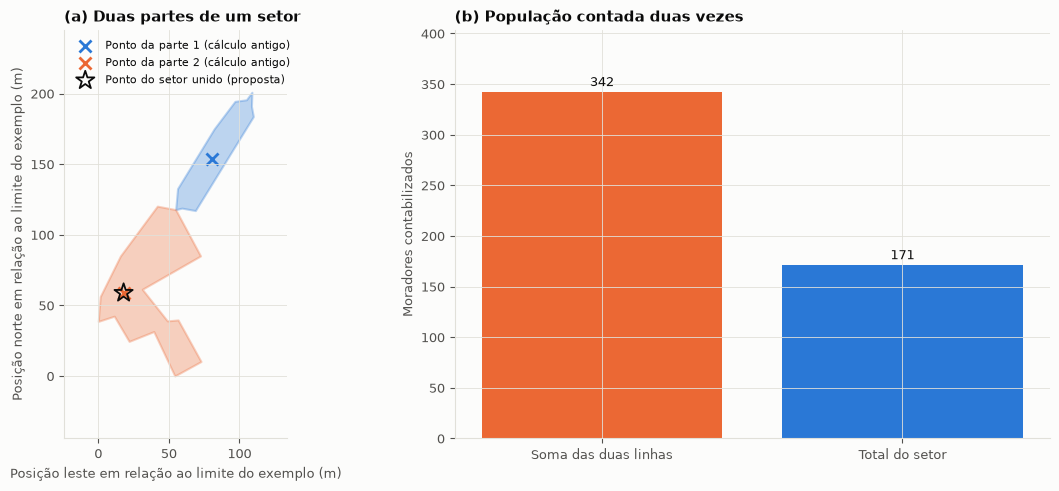

**Como ler:** as cores identificam partes do mesmo setor, não dois setores. Os pontos marcados com × geraram distâncias distintas no processamento anterior. A estrela ilustra o ponto da geometria unida; ela pode coincidir com o ponto de uma das partes. O gráfico de barras mostra apenas a repetição dos totais. Não sabemos como os moradores se distribuem entre as partes.

In [8]:
codigo_bh = "310620005670833"
linhas_bh = brutos["SUS"].loc[brutos["SUS"].CD_SETOR == codigo_bh].copy()
partes_bh = gpd.read_file(
    RAIZ / "dados" / "ibge" / "setores_gpkg" / "MG_setores_CD2022.gpkg",
    where=f"CD_SETOR='{codigo_bh}'", columns=["CD_SETOR", "AREA_KM2"]
).to_crs(32723)

populacao_oficial = linhas_bh.populacao.iloc[0]
area_oficial = linhas_bh.AREA_KM2.iloc[0]
comparacao_totais = pd.DataFrame([
    {"situação": "Soma das linhas atuais", "população": linhas_bh.populacao.sum(),
     "área_km2": linhas_bh.AREA_KM2.sum()},
    {"situação": "Uma vez por setor (proposta)", "população": populacao_oficial,
     "área_km2": area_oficial},
]).set_index("situação")
display(comparacao_totais)
display(linhas_bh[["CD_SETOR", "populacao", "AREA_KM2", "CO_CNES", "d_m"]])

# A união abaixo serve somente para ilustrar a proposta no gráfico.
# Nenhuma associação ou tabela de distâncias é modificada.
geometria_unida_bh = partes_bh.geometry.union_all()
ponto_proposto_bh = geometria_unida_bh.representative_point()
pontos_por_parte_bh = partes_bh.geometry.representative_point()
origem_x, origem_y = partes_bh.total_bounds[:2]
def coordenadas_locais(geometria):
    from shapely.affinity import translate
    return translate(geometria, xoff=-origem_x, yoff=-origem_y)

partes_locais_bh = partes_bh.copy()
partes_locais_bh.geometry = partes_bh.geometry.map(coordenadas_locais)
pontos_locais_bh = pontos_por_parte_bh.map(coordenadas_locais)
ponto_local_proposto_bh = coordenadas_locais(ponto_proposto_bh)

fig, (ax_mapa, ax_totais) = plt.subplots(1, 2, figsize=(12, 5))
cores = [estilo.AZUL, estilo.LARANJA]
for i, (_, parte) in enumerate(partes_locais_bh.iterrows()):
    gpd.GeoSeries([parte.geometry], crs=partes_bh.crs).plot(
        ax=ax_mapa, color=cores[i], alpha=0.3, edgecolor=cores[i], linewidth=1.5
    )
for i, ponto in enumerate(pontos_locais_bh):
    ax_mapa.scatter(ponto.x, ponto.y, color=cores[i], marker="x", s=75,
                    label=f"Ponto da parte {i+1} (cálculo antigo)")
ax_mapa.scatter(ponto_local_proposto_bh.x, ponto_local_proposto_bh.y,
                marker="*", s=190, facecolor="none", edgecolor=estilo.TEXTO,
                linewidth=1.3, label="Ponto do setor unido (proposta)")
ax_mapa.set_title("(a) Duas partes de um setor")
ax_mapa.set_xlabel("Posição leste em relação ao limite do exemplo (m)")
ax_mapa.set_ylabel("Posição norte em relação ao limite do exemplo (m)")
ax_mapa.legend(fontsize=8, loc="upper left")
ax_mapa.margins(0.22)

ax_totais.bar(["Soma das duas linhas", "Total do setor"], [linhas_bh.populacao.sum(), populacao_oficial],
             color=[estilo.LARANJA, estilo.AZUL])
for i, total in enumerate([linhas_bh.populacao.sum(), populacao_oficial]):
    ax_totais.text(i, total + 6, f"{int(total)}", ha="center")
ax_totais.set_ylim(0, linhas_bh.populacao.sum() * 1.18)
ax_totais.set_ylabel("Moradores contabilizados")
ax_totais.set_title("(b) População contada duas vezes")
fig.tight_layout()
plt.show()

display(Markdown(
    "**Como ler:** as cores identificam partes do mesmo setor, não dois setores. "
    "Os pontos marcados com × geraram distâncias distintas no processamento anterior. "
    "A estrela ilustra o ponto da geometria unida; ela pode coincidir com o ponto de uma das partes. "
    "O gráfico de barras mostra apenas a repetição dos totais. "
    "Não sabemos como os moradores se distribuem entre as partes."
))


### Por que isso afeta área e densidade?

Se o total de população e de área fosse simplesmente duplicado em um setor isolado, a razão população/área continuaria igual. **Isso não torna a repetição inofensiva.** Na L2, somamos setores para formar a área de atendimento de cada unidade:

- a população e a área de alguns setores seriam contadas mais vezes que as de outros;
- partes de um mesmo setor podem ter sido atribuídas a unidades diferentes;
- como $D=1/A$, repetir a área muda a densidade de pronto-atendimentos.

**Alternativa à união:** tratar cada parte separadamente exigiria saber sua população e sua área própria, em vez de repetir os totais do setor. Não temos uma distribuição observada de moradores por parte; dividi-los igualmente introduziria outra hipótese.

**Limite da correção aprovada:** mesmo com as partes unidas, representar todos os moradores por um ponto continua sendo uma aproximação. O gráfico não permite afirmar em qual parte eles vivem. A autora autorizou essa correção após a discussão.


## 9. Entender as duas unidades ligadas ao mesmo nó

As coordenadas corrigidas situam os dois estabelecimentos de Bom Jesus a aproximadamente **126 m em linha reta** um do outro. Eles **não são o mesmo estabelecimento nem estão no mesmo ponto**. Na aproximação anterior, ambos foram ligados ao mesmo nó da rede de ruas.

O código antigo mantém a primeira unidade ligada ao nó como fonte do Dijkstra. Na versão com todos, ela é o **Pronto Atendimento de Campanha Bom Jesus**; na versão só SUS, é o **Pronto Atendimento Bom Jesus**. O rótulo SUS é o do cadastro utilizado: não estamos reclassificando os estabelecimentos a partir de seus nomes.

O mapa abaixo mostra as duas coordenadas, o nó compartilhado, os trechos de rua próximos e as ligações retas usadas como aproximação. Essas ligações não são trajetos observados de entrada nos estabelecimentos.


Separação entre as coordenadas: 126.5 m


,CO_CNES,NO_FANTASIA,atende_sus,no,ligacao_m
107,4758749,PRONTO ATENDIMENTO DE CAMPANHA BOM JESUS,False,445820977,61.208237
164,6537650,PRONTO ATENDIMENTO BOM JESUS,True,445820977,92.298948


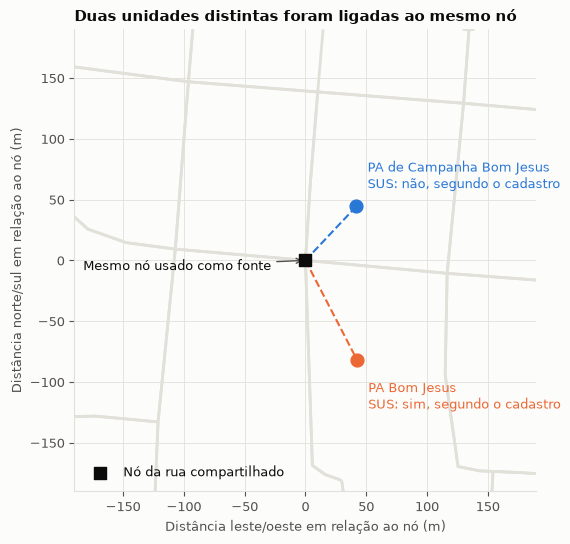

**Como ler:** os círculos são as unidades; o quadrado é o nó da rede ao qual ambas foram ligadas. As linhas tracejadas são conexões geométricas até esse nó, não ruas ou entradas confirmadas. A proximidade no grafo limita a capacidade do método anterior de distinguir suas áreas de atendimento.

In [9]:
codigos_bom_jesus = ["4758749", "6537650"]
bom_jesus = pa_poa.loc[pa_poa.CO_CNES.isin(codigos_bom_jesus)].copy()
assert bom_jesus.no.nunique() == 1
no_compartilhado = int(bom_jesus.no.iloc[0])
x_no, y_no = grafo_poa.nodes[no_compartilhado]["x"], grafo_poa.nodes[no_compartilhado]["y"]
distancia_entre_unidades = bom_jesus.geometry.iloc[0].distance(bom_jesus.geometry.iloc[1])
print(f"Separação entre as coordenadas: {distancia_entre_unidades:.1f} m")
display(bom_jesus[["CO_CNES", "NO_FANTASIA", "atende_sus", "no", "ligacao_m"]])

# Coordenadas relativas ao nó para mostrar distâncias em metros.
from shapely.geometry import box, LineString
from shapely.affinity import translate
janela_bom_jesus = box(x_no-190, y_no-190, x_no+190, y_no+190)
ruas_proximas = []
for u, v, dados_aresta in grafo_poa.edges(data=True):
    linha = dados_aresta.get("geometry")
    if linha is None:
        linha = LineString([(grafo_poa.nodes[u]["x"], grafo_poa.nodes[u]["y"]),
                            (grafo_poa.nodes[v]["x"], grafo_poa.nodes[v]["y"])])
    if linha.intersects(janela_bom_jesus):
        ruas_proximas.append(translate(linha.intersection(janela_bom_jesus), xoff=-x_no, yoff=-y_no))

fig, ax = plt.subplots(figsize=(8, 6))
if ruas_proximas:
    gpd.GeoSeries(ruas_proximas, crs=bom_jesus.crs).plot(
        ax=ax, color=estilo.GRADE, linewidth=2
    )
rotulos = {
    "4758749": "PA de Campanha Bom Jesus\nSUS: não, segundo o cadastro",
    "6537650": "PA Bom Jesus\nSUS: sim, segundo o cadastro",
}
for i, (_, unidade) in enumerate(bom_jesus.iterrows()):
    x_local, y_local = unidade.geometry.x-x_no, unidade.geometry.y-y_no
    ax.plot([0, x_local], [0, y_local], "--", color=cores[i], linewidth=1.5)
    ax.scatter(x_local, y_local, s=85, color=cores[i], zorder=4)
    deslocamento = (8, 13) if y_local >= 0 else (8, -35)
    ax.annotate(rotulos[unidade.CO_CNES], (x_local, y_local), xytext=deslocamento,
                textcoords="offset points", fontsize=9, color=cores[i])
ax.scatter(0, 0, color=estilo.TEXTO, marker="s", s=70, zorder=5, label="Nó da rua compartilhado")
ax.annotate("Mesmo nó usado como fonte", (0, 0), xytext=(-160, -7),
            textcoords="offset points", fontsize=9,
            arrowprops={"arrowstyle": "->", "color": estilo.TEXTO_2})
ax.set_xlim(-190, 190)
ax.set_ylim(-190, 190)
ax.set_aspect("equal")
ax.set_xlabel("Distância leste/oeste em relação ao nó (m)")
ax.set_ylabel("Distância norte/sul em relação ao nó (m)")
ax.set_title("Duas unidades distintas foram ligadas ao mesmo nó")
ax.legend(loc="lower left")
plt.show()

display(Markdown(
    "**Como ler:** os círculos são as unidades; o quadrado é o nó da rede ao qual ambas foram ligadas. "
    "As linhas tracejadas são conexões geométricas até esse nó, "
    "não ruas ou entradas confirmadas. A proximidade no grafo limita "
    "a capacidade do método anterior de distinguir suas áreas de atendimento."
))


### Alternativas para discutir antes do ajuste

| Alternativa | Como funciona | O que muda e qual é o limite |
|---|---|---|
| **A. Área compartilhada com duas unidades — aprovada** | Manter o nó como ponto de acesso comum e registrar que ele representa duas unidades na versão com todos. Para essa área, a densidade de estabelecimentos é $D=m/A$, com $m=2$; nas demais, $m=1$. | Preserva a contagem das duas unidades na densidade, mas não distingue suas áreas individuais nem considera capacidade. Adaptação de $D=1/A$ aprovada pela autora. São 273 áreas representadas na rede, para 274 estabelecimentos. |
| **B. Detalhar a ligação de cada unidade à rua** | Representar cada unidade a partir de sua projeção no segmento de rua próximo, inserindo pontos na rede e respeitando as direções das vias. Recalcular as rotas de Porto Alegre com Dijkstra. | Pode distinguir as posições na rede sem agrupar as unidades. Exige mais processamento e cuidado com as ligações e as mãos de direção. Coordenadas próximas não informam entradas reais. Também não garante uma área com setores para cada unidade: um PA pode continuar não sendo o mais próximo de nenhum ponto de setor. |
| **C. Manter o cálculo anterior e explicitar a limitação** | Manter uma fonte por nó e documentar o estabelecimento que não recebeu área. | Evita mudar a regra nesta etapa, mas a regressão da versão com todos descreve as áreas representadas, sem incorporar separadamente a segunda unidade. |

Na versão **só SUS**, apenas uma dessas duas unidades entra, segundo o cadastro. Portanto esse compartilhamento específico afeta a versão com todos. A correção dos setores divididos em partes afeta ambas.

**Decisão da autora em 04/11/2026: alternativa A.** Esta seção documenta a discussão. A aplicação está em [01_correcao_setores.ipynb](01_correcao_setores.ipynb) e o ajuste está em [02_L2_densidade.ipynb](02_L2_densidade.ipynb). Este notebook mantém a auditoria dos dados originais.

**Justificativa da alternativa escolhida:** contar as duas unidades na área compartilhada preserva o cadastro e explicita a resolução limitada da rede. A adaptação $D=m/A$ e a ausência de áreas individuais devem aparecer nos métodos e nas limitações do artigo.
